# Diabetes Risk Prediction
### Exploratory Analysis and Model Comparison

This DataSC project uses the CDC's 2015 BRFSS health-indicator dataset to examine relationships between health, lifestyle, socioeconomic factors, and reported diabetes status.

**Target:** `Diabetes_binary`, where `0` means no diabetes and `1` means prediabetes or diabetes.

**How to use this notebook:** Place `diabetes_binary_health_indicators_BRFSS2015.csv` in the notebook's working directory and run the cells from top to bottom. Markdown explanations describe the methods and interpret the saved results.


### Setup

Import the libraries used to prepare the data, create plots, and split the dataset into training and test sets.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

## 1. Correlation Heatmap

Explore how selected health, lifestyle, and demographic indicators relate to the target and to one another. The analysis below interprets the saved heatmap.


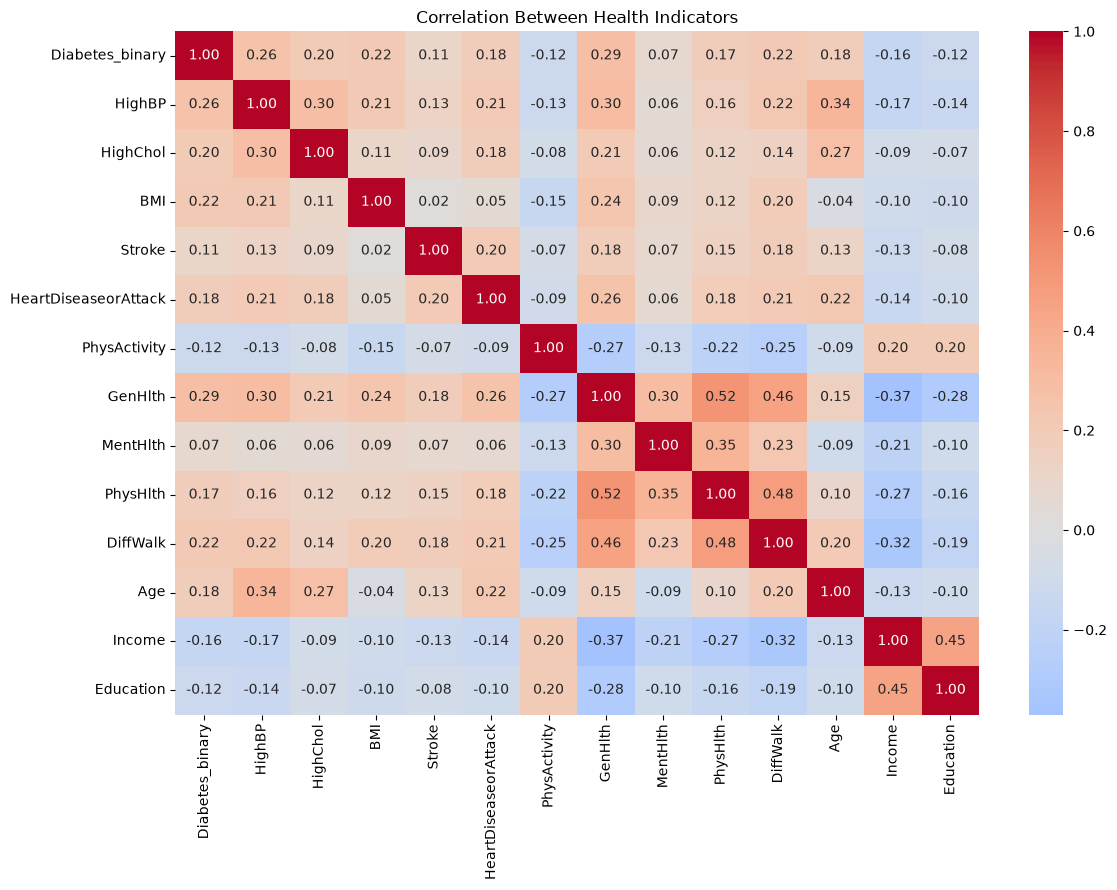

In [2]:
correlation_columns = [
    "Diabetes_binary", "HighBP", "HighChol", "BMI", "Stroke",
    "HeartDiseaseorAttack", "PhysActivity", "GenHlth",
    "MentHlth", "PhysHlth", "DiffWalk", "Age", "Income", "Education"
]

df = pd.read_csv("diabetes_binary_health_indicators_BRFSS2015.csv")

corr_data = df[correlation_columns].astype(float)
corr_matrix = corr_data.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)
plt.title("Correlation Between Health Indicators")
plt.tight_layout()
plt.show()

### Analysis: Correlation heatmap

In the saved plot, general health (0.29) and high blood pressure (0.26) have the largest positive correlations with the target among the shown predictors. BMI and difficulty walking are both about 0.22. Income (-0.16) and physical activity (-0.12) have negative associations. These are modest pairwise relationships, not evidence of causation.


## 2. Distributions and Group Comparisons

Examine the overall BMI distribution, followed by positive-class rates across blood-pressure and general-health groups. In this dataset, the positive class combines prediabetes and diabetes.


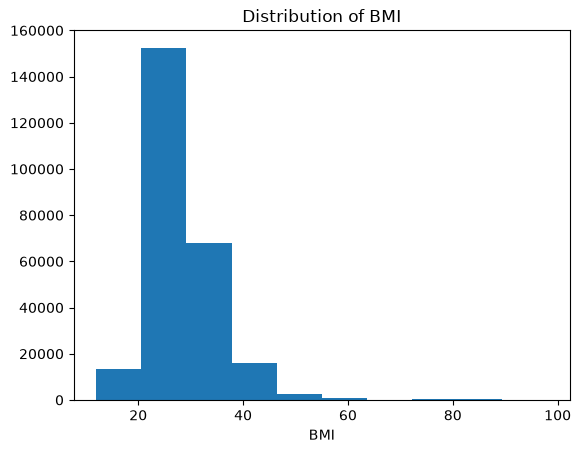

In [3]:
column = "BMI"

plt.hist(df[column])
plt.title(f"Distribution of {column}")
plt.xlabel(column)
plt.show()

### Analysis: BMI distribution

The histogram is right-skewed, with most observations around BMI 20-40 and a small number of much higher values. It describes the full sample; it does not compare BMI between people with and without diabetes.


Diabetes_binary        0.0        1.0
HighBP                               
0.0              93.964833   6.035167
1.0              75.554310  24.445690


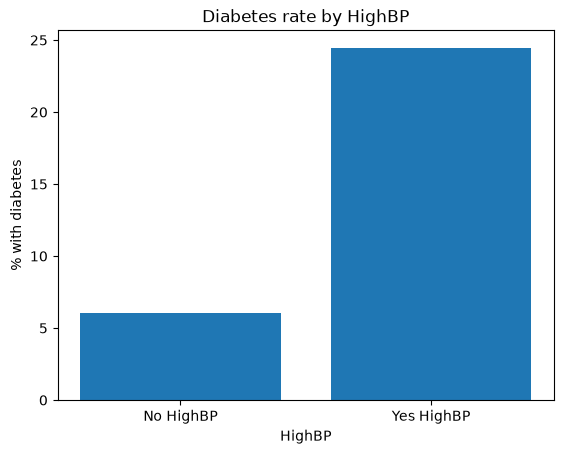

In [4]:
column = "HighBP"

# Each row adds to 100%; column 1 is the percentage with diabetes
proportions = pd.crosstab(
    df[column],
    df["Diabetes_binary"],
    normalize="index"
) * 100

print(proportions)

rate = proportions[1]

plt.bar(rate.index.astype(str), rate.values)
plt.title(f"Diabetes rate by {column}")
plt.xticks([0, 1], ["No HighBP", "Yes HighBP"])
plt.xlabel(column)
plt.ylabel("% with diabetes")
plt.show()

### Analysis: High blood pressure

The positive-class rate is 24.4% among respondents with high blood pressure, compared with 6.0% among those without it: roughly four times as high. Row normalization makes these within-group percentages, so the comparison is not simply a result of different group sizes. This observed association does not show that high blood pressure causes diabetes.


Diabetes_binary        0.0        1.0
GenHlth                              
1.0              97.483388   2.516612
2.0              92.837098   7.162902
3.0              82.210560  17.789440
4.0              68.989547  31.010453
5.0              62.105786  37.894214


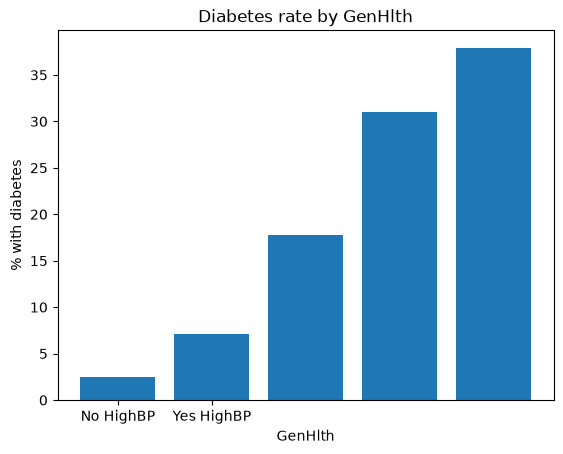

In [5]:
column = "GenHlth"

# Each row adds to 100%; column 1 is the percentage with diabetes
proportions = pd.crosstab(
    df[column],
    df["Diabetes_binary"],
    normalize="index"
) * 100

print(proportions)

rate = proportions[1]

plt.bar(rate.index.astype(str), rate.values)
plt.title(f"Diabetes rate by {column}")
plt.xticks([0, 1], ["No HighBP", "Yes HighBP"])
plt.xlabel(column)
plt.ylabel("% with diabetes")
plt.show()

### Analysis: Self-reported general health

GenHlth runs from 1 (excellent) to 5 (poor). The printed positive-class rates rise across these categories: 2.5%, 7.2%, 17.8%, 31.0%, and 37.9%. Poorer reported general health is associated with higher prevalence. Plot note: the existing first two tick labels refer to HighBP, but this cell actually groups by GenHlth. Use the printed table to read the groups.


## 3. Logistic Regression

Prepare the data, create a stratified training/test split, and fit a class-weighted logistic regression model using 10 selected predictors. Predictions use a probability-score threshold of 0.55.


### Data preparation: Categorical variables

Reload the original data and mark the listed binary fields as categories. The saved output contains 22 columns, including the target. Later, get_dummies() converts categorical predictors into indicator columns. Ordinal fields such as Age, Income, and GenHlth remain numeric codes.


In [6]:
df = pd.read_csv("diabetes_binary_health_indicators_BRFSS2015.csv")

# List of variables that are logically binary/categorical (factor in R)
binary_vars = [
    "Diabetes_binary", "HighBP", "HighChol", "CholCheck", "Smoker", "Stroke",
    "HeartDiseaseorAttack", "PhysActivity", "Fruits", "Veggies",
    "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex",
]

# Convert those columns to pandas 'category' dtype (equivalent of as.factor)
for col in binary_vars:
    df[col] = df[col].astype("category")

print(df.head())
print(df.dtypes)

  Diabetes_binary HighBP HighChol CholCheck   BMI Smoker Stroke  \
0             0.0    1.0      1.0       1.0  40.0    1.0    0.0   
1             0.0    0.0      0.0       0.0  25.0    1.0    0.0   
2             0.0    1.0      1.0       1.0  28.0    0.0    0.0   
3             0.0    1.0      0.0       1.0  27.0    0.0    0.0   
4             0.0    1.0      1.0       1.0  24.0    0.0    0.0   

  HeartDiseaseorAttack PhysActivity Fruits  ... AnyHealthcare NoDocbcCost  \
0                  0.0          0.0    0.0  ...           1.0         0.0   
1                  0.0          1.0    0.0  ...           0.0         1.0   
2                  0.0          0.0    1.0  ...           1.0         1.0   
3                  0.0          1.0    1.0  ...           1.0         0.0   
4                  0.0          1.0    1.0  ...           1.0         0.0   

  GenHlth MentHlth  PhysHlth  DiffWalk  Sex   Age Education  Income  
0     5.0     18.0      15.0       1.0  0.0   9.0       4.0     

In [7]:
# Clean up code
# check missing values per column
print(df.isna().sum())

# remove rows with any missing values
df = df.dropna()

Diabetes_binary         0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64


### Analysis: Missing values

The saved output shows zero missing values in every column. Therefore, dropna() does not remove any observations in this run.


### Training and test split

Reserve 20% of the observations for testing and use 80% for training. Stratification approximately preserves the target's class proportions. The fixed random state makes this particular split reproducible.


In [8]:
diabetic_train, diabetic_test = train_test_split(
    df, test_size=0.2, stratify=df["Diabetes_binary"], random_state=1
)

### Model inputs: Logistic regression

This model uses 10 selected predictors; BMI is not included here. Dummy encoding represents categorical predictors, and reindexing aligns the test columns with the training columns. Age, Income, and GenHlth remain numeric, so their code steps enter the model as numeric changes. LASSO and random forest later use a broader set of 21 predictors.


In [9]:
# Build the design (model) matrix for the chosen predictors
predictors = [
    "HighBP", "HighChol", "HvyAlcoholConsump", "Stroke", "DiffWalk",
    "Age", "Income", "CholCheck", "GenHlth", "PhysActivity",
]

X_train = pd.get_dummies(diabetic_train[predictors], drop_first=True)
y_train = diabetic_train["Diabetes_binary"].astype(int)

X_test = pd.get_dummies(diabetic_test[predictors], drop_first=True)
# Make sure the test columns match the training columns exactly
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
y_test = diabetic_test["Diabetes_binary"].astype(int)

### Class balancing

Give each training row the inverse of its class frequency. This assigns greater weight to observations in the smaller class and gives both classes the same total weight. These are class-balancing weights, not the CDC survey's population sampling weights.


In [10]:
class_counts = y_train.value_counts()
inv_weights = 1 / class_counts
sample_weights = y_train.map(inv_weights)

### Fit logistic regression

Rescale the weights to an average of one and train the classifier. The weighting gives positive cases more influence during fitting. The model uses LogisticRegression's default regularization. Its weighted probability scores are not validated clinical risk estimates.


In [11]:
from sklearn.linear_model import LogisticRegression

# Scale the weights so the average weight is 1 (the smaller group still counts more)
scaled_weights = sample_weights * len(y_train) / 2

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train, sample_weight=scaled_weights)

print("Model trained!")

Model trained!


In [12]:
pred_probs = model.predict_proba(X_test)[:, 1]   # probability of diabetes
pred_class = (pred_probs >= 0.55).astype(int)    # 1 = diabetes, 0 = no diabetes

from sklearn.metrics import accuracy_score, precision_score, recall_score

accuracy = accuracy_score(y_test, pred_class)
precision = precision_score(y_test, pred_class)
recall = recall_score(y_test, pred_class)

print("Accuracy vs. Precision vs. Recall")
print(f"  Accuracy : {accuracy:.3f}")
print(f"  Precision: {precision:.3f}")
print(f"  Recall   : {recall:.3f}")

Accuracy vs. Precision vs. Recall
  Accuracy : 0.748
  Precision: 0.317
  Recall   : 0.698


### Analysis: Logistic regression results

At the 0.55 threshold, the saved accuracy is 74.8%, precision is 31.7%, and recall is 69.8%. The model detects about seven in ten positive cases, but only about one in three positive predictions is correct. The 0.55 cutoff is set in the code; it has not been shown to be optimal.


## 4. Lasso Logistic Regression

Use all 21 predictors and an L1 penalty to shrink coefficients, potentially setting some to zero. Select the penalty strength with cross-validation and evaluate the resulting predictions on the same held-out test split.


### Model inputs: Lasso

Use every column except the target, producing 21 predictor columns. The training/test split is the same as before, and dummy columns are aligned again. Because this feature set differs from the first logistic model's, performance differences also reflect the choice of predictors.


In [13]:
# Build the design (model) matrix for the chosen predictors
# Lasso gets ALL the columns (every column except the answer) and decides which ones matter
predictors = [col for col in df.columns if col != "Diabetes_binary"]

X_train = pd.get_dummies(diabetic_train[predictors], drop_first=True)
y_train = diabetic_train["Diabetes_binary"].astype(int)

X_test = pd.get_dummies(diabetic_test[predictors], drop_first=True)
# Make sure the test columns match the training columns exactly
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
y_test = diabetic_test["Diabetes_binary"].astype(int)

### Scaling the predictors

Learn the feature means and standard deviations from the training data, then apply that same transformation to the test data. Scaling puts the predictors on comparable scales for the L1 penalty. Test observations are not used to fit the scaler.


In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler() # adjusts each coloumn so its average is approximately 0 and its standard deviation is 1

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X_train.columns, index=X_test.index
)

In [15]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # hides a harmless version warning

from sklearn.linear_model import LogisticRegressionCV
scaled_weights = sample_weights * len(y_train) / 2

model = LogisticRegressionCV(
    Cs=10,               # try 10 penalty strengths
    cv=5,                # 5-fold cross-validation
    penalty="l1",        # "l1" means lasso
    solver="liblinear",
    scoring="roc_auc",   # pick the strength that ranks people best
    max_iter=1000,
    random_state=1,
)
model.fit(X_train_scaled, y_train, sample_weight=scaled_weights)

print("Model trained!")
print("Best penalty strength (C):", model.C_[0], "(smaller C = stronger penalty)")

Model trained!
Best penalty strength (C): 0.005994842503189409 (smaller C = stronger penalty)


### Analysis: Lasso tuning

This is L1-regularized logistic regression. Five-fold cross-validation compares 10 C values using ROC AUC, a measure of ranking performance. The saved run selects C about 0.006; smaller C means a stronger penalty. The warning filter suppresses all FutureWarning messages. Method note: scaling happens before internal cross-validation, so the validation folds influence scaling statistics. The held-out test set is still excluded from scaler fitting.


Columns lasso dropped (coefficient = 0): ['Smoker_1.0']
Columns kept: 20 out of 21


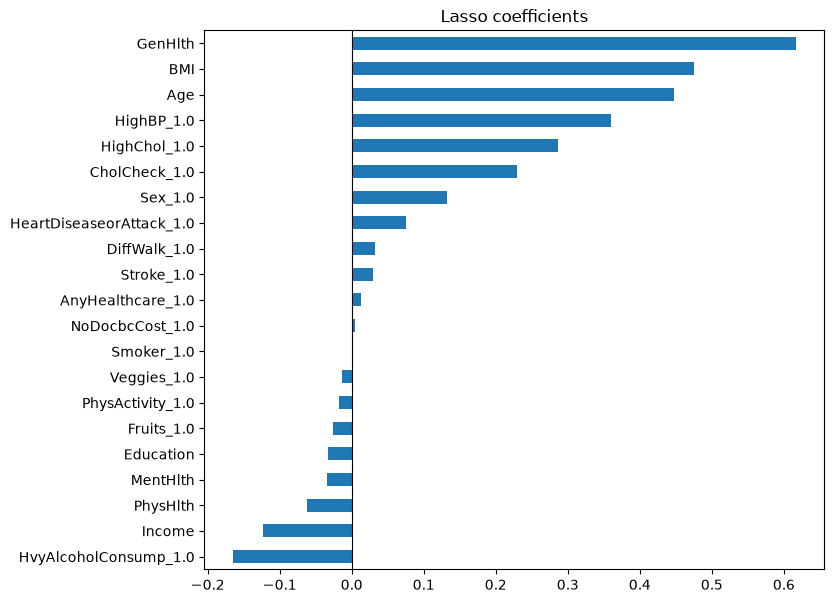

In [16]:
coefs = pd.Series(model.coef_[0], index=X_train.columns).sort_values()

dropped = list(coefs[coefs == 0].index)
print("Columns lasso dropped (coefficient = 0):", dropped if dropped else "none, lasso kept every column")
print("Columns kept:", len(coefs) - len(dropped), "out of", len(coefs))

coefs.plot(kind="barh", figsize=(8, 7), title="Lasso coefficients")
plt.axvline(0, color="black", linewidth=0.8)
plt.show()

### Analysis: Lasso coefficients

The fitted penalty sets Smoker_1.0 to zero and retains 20 of 21 columns. General health, BMI, and age have the largest positive standardized coefficients in the saved chart. Income has a negative coefficient. Coefficient signs describe conditional model associations, not causes. A zero coefficient does not establish that smoking is unrelated to diabetes.


In [17]:
pred_probs = model.predict_proba(X_test_scaled)[:, 1]   # probability of diabetes
pred_class = (pred_probs >= 0.55).astype(int)          # 1 = diabetes, 0 = no diabetes

from sklearn.metrics import accuracy_score, precision_score, recall_score

accuracy = accuracy_score(y_test, pred_class)
precision = precision_score(y_test, pred_class)
recall = recall_score(y_test, pred_class)

print("Accuracy vs. Precision vs. Recall")
print(f"  Accuracy : {accuracy:.3f}")
print(f"  Precision: {precision:.3f}")
print(f"  Recall   : {recall:.3f}")

Accuracy vs. Precision vs. Recall
  Accuracy : 0.762
  Precision: 0.334
  Recall   : 0.716


### Analysis: Lasso results

At the same 0.55 cutoff, accuracy is 76.2%, precision is 33.4%, and recall is 71.6%. These are the highest accuracy and precision among the three saved model results. Precision remains low: about two-thirds of positive predictions are false positives.


## 5. Random Forest

Fit a weighted ensemble of decision trees using all 21 predictors, examine feature importance, and compare its held-out performance at the same 0.55 threshold.


### Fit random forest

Train 100 trees with a maximum depth of eight. This cell reuses the unscaled, all-predictor X_train created in the LASSO section and the inverse-frequency training weights. Tree predictions are combined to capture relationships that can be more complex than a linear score.


In [18]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,   # number of trees
    max_depth=8,        # each tree asks at most 8 questions in a row
    random_state=1,
    n_jobs=-1,          # use all CPU cores
)
model.fit(X_train, y_train, sample_weight=sample_weights)

print("Model trained!")

Model trained!


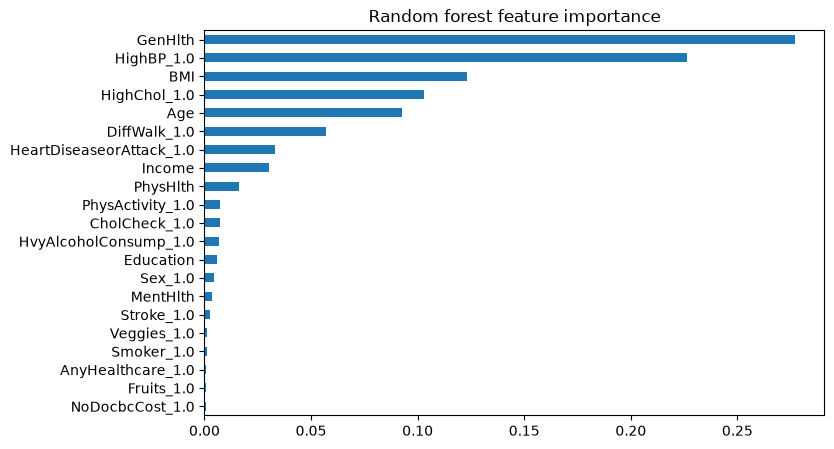

In [19]:
importance = pd.Series(model.feature_importances_, index=X_train.columns).sort_values()

importance.plot(kind="barh", figsize=(8, 5), title="Random forest feature importance")
plt.show()

### Analysis: Random forest feature importance

General health, high blood pressure, and BMI have the highest importance scores in the saved chart, followed by high cholesterol and age. These impurity-based scores show how much features help split the trees; they do not show whether a feature raises or lowers predictions. They can also favor variables with more possible split points.


In [20]:
pred_probs = model.predict_proba(X_test)[:, 1]   # probability of diabetes
pred_class = (pred_probs >= 0.55).astype(int)    # 1 = diabetes, 0 = no diabetes

# Look at the first 10 predictions next to the real answers
pd.DataFrame({
    "probability": pred_probs[:10].round(3),
    "predicted": pred_class[:10],
    "actual": y_test.values[:10],
})

from sklearn.metrics import accuracy_score, precision_score, recall_score

accuracy = accuracy_score(y_test, pred_class)
precision = precision_score(y_test, pred_class)
recall = recall_score(y_test, pred_class)

print("Accuracy vs. Precision vs. Recall")
print(f"  Accuracy : {accuracy:.3f}")
print(f"  Precision: {precision:.3f}")
print(f"  Recall   : {recall:.3f}")

Accuracy vs. Precision vs. Recall
  Accuracy : 0.757
  Precision: 0.331
  Recall   : 0.728


### Analysis: Random forest results

Accuracy is 75.7%, precision is 33.1%, and recall is 72.8% at the 0.55 cutoff. This model has the highest saved recall, 1.2 percentage points above LASSO, with slightly lower accuracy and precision. Which result is preferable depends on the importance of missed cases relative to false positives. One split does not establish a universal winner.


## 6. Conclusion

### Model comparison

The following values come from the saved outputs in this notebook. Precision and recall refer to the positive class: prediabetes or diabetes.

| Model | Accuracy | Precision | Recall |
| --- | ---: | ---: | ---: |
| Logistic regression | 74.8% | 31.7% | 69.8% |
| Lasso logistic regression | **76.2%** | **33.4%** | 71.6% |
| Random forest | 75.7% | 33.1% | **72.8%** |

LASSO has the highest saved accuracy and precision, while random forest identifies the greatest proportion of positive cases. All three detect roughly seven in ten positive cases, with about one-third of their positive predictions correct. The results illustrate the tradeoff between identifying cases and generating false positives.

### What the analysis suggests

- General health, blood pressure, and BMI repeatedly stand out in the exploratory analysis or fitted models.
- The Lasso model retains 20 of 21 predictors, with only the smoking indicator assigned a zero coefficient.
- Reported associations and model importance scores do not establish causation.

### Interpreting the comparison

The first logistic model uses 10 predictors, while Lasso and random forest use all 21. Their differences reflect both the modeling approach and the selected inputs. Results come from one held-out split, and the 0.55 threshold has not been established as optimal.

The target describes existing survey-reported status, so this analysis does not measure future diabetes onset. Class-weighted probability scores have not been validated as individual clinical risk estimates.
